Target of this script is to write a file with the following

- username: username
- comment: str (original comment)
- reasoning: str (cleaned up comment which could be used for training)
- label: str
- group_validated_label: bool (for entries where annotators disagreed or the gold label was in disagreement, these were reviewed as a group). 
- gold_label_name: str the final label of the entry (including group review if applicable)
- round: date
- claim.hash: int
- evidence.hash: int
- display_id: str
- build_version: str (the version of the build that was used to generate the doccano input)

In [1]:
import pandas as pd
import os
import glob
from doccano.util import read_error_review_results, read_relabelling_data

MAJORITY_VOTE = 2  # must have 2 users in agreement

def relative_path(filename):
    """set the path relative to the repo base directory"""
    return os.path.join(os.path.abspath(''), '..', '..', '..', filename)


load and clean IAv2 round annotations

In [2]:

doc_df = read_relabelling_data(glob.glob(relative_path('data/doccano/2023.10.20_IAv2_civicfact2023.10.20/subset-*/*.jsonl')), MAJORITY_VOTE).rename(columns={'example_id': 'display_id'})
doc_df['round'] = 'IAv2_civicfact2023.10.20'
doc_df = doc_df.rename(columns={col : f'doccano.{col}'for col in doc_df.columns if col not in ['display_id']})
print(doc_df.columns)

build = []
for filename in glob.glob(relative_path('builds/civicfact-2023.10.20/hypothesis-dump.merged.parsed.fulltext-matched.build.with-neutral.partitioned.jsonl.gz')):
    build.append(pd.read_json(filename, lines=True))
build_df = pd.concat(build)
build_df['build_version'] = 'v2023.10.20'
print(build_df.columns)
print(build_df.gold_label_name.value_counts())

print('docs:', doc_df.shape[0])
size = doc_df.shape[0]
doc_df = doc_df.merge(build_df, how='left', on='display_id', validate='many_to_one')
assert size == doc_df.shape[0]
doc_df[['id', 'display_id', 'doccano.username', 'doccano.gold_label_name', 'doccano.label', 'gold_label_name']]

group_df = read_error_review_results(glob.glob(relative_path('data/doccano/IAv2_error_review/*.jsonl')))
group_df['review.round'] = 'IAv2_error_review'
group_df['review.group_review'] = True

doc_df = doc_df.merge(group_df, validate='many_to_one', how='left')
doc_df['review.group_review'] = doc_df['review.group_review'].fillna(False)
doc_df[['claim', 'evidence']]

reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-0/Mariam_Khanfar.jsonl
reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-0/admin.jsonl
reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-1/admin.jsonl
reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-1/kkrysiak.jsonl
reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-2/jsaliba10.jsonl
reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-2/admin.jsonl
reading /projects/creisle_prj/git/thesis_work/src/analysis_scripts/../../data/doccano/IAv2_civicfact2023.10.20/subset-3/obigriffith.jsonl
reading /projects/creisle_prj/git/thesis_work/src/anal

,claim,evidence
0,"[{'content': [['molecularProfile', 'VHL H115Q ...",[{'content': 'C>A: p.H115Q) was revealed to be...
1,"[{'content': [['molecularProfile', 'VHL H115Q ...",[{'content': 'C>A: p.H115Q) was revealed to be...
2,"[{'content': [['molecularProfile', 'VHL H115Q ...",[{'content': 'C>A: p.H115Q) was revealed to be...
3,"[{'content': [['molecularProfile', 'FGFR3 K650...",[{'content': 'A patient suffering from skeleta...
4,"[{'content': [['molecularProfile', 'FGFR3 K650...",[{'content': 'A patient suffering from skeleta...
...,...,...
893,"[{'content': [['molecularProfile', 'ATRX Delet...","[{'content': 'Finally, we demonstrate that mul..."
894,"[{'content': [['molecularProfile', 'ATRX Delet...","[{'content': 'Finally, we demonstrate that mul..."
895,"[{'content': [['molecularProfile', 'XRCC1 Q399...","[{'content': 'In the multivariate Cox model, w..."
896,"[{'content': [['molecularProfile', 'XRCC1 Q399...","[{'content': 'In the multivariate Cox model, w..."


calculate the final label using the majority votes and the review labels

In [3]:
df = doc_df.copy()
df['freq'] = 1

df['final_label'] = df.gold_label_name
df['review.gold_label_incorrect'] = df['review.labels'].apply(lambda review_labels: 'Gold Label Incorrect' in review_labels if isinstance(review_labels, list) else False)
df.loc[df['review.gold_label_incorrect'], 'final_label'] = df[df['review.gold_label_incorrect']]['doccano.example.majority_label_name']

# did we miss any discrepancies in review
misses = df[(df['review.group_review'] == False ) & (df['doccano.example.majority_label_name'] != df['gold_label_name'])].shape[0]
assert misses == 0

def choose_status(row):
    changed = row['final_label'] != row['gold_label_name']
    agreed = row['doccano.example.majority_label_name'] == row['gold_label_name']
    majority_reached = row['doccano.example.majority_label_name'] != 'NO MAJORITY'

    if not majority_reached:
        return 'no majority'
    if not agreed:
        if changed:
            return 'gold label corrected'
        return 'curator error'
    return 'agreement'

def choose_category(row):
    if row['hypothesis.username'] == 'factbot':
        return 'bot generated'
    if row['evidence.source'] == 'civic':
        return 'civic description'
    if row['is_flagged'] == True:
        return 'flagged'
    return f'other - votes:{row["doccano.example.majority_label_votes"]} chose {row["doccano.example.majority_label_name"]}'

df['status'] = df.apply(choose_status, axis=1)
df['category'] = df.apply(choose_category, axis=1)


at what rate did the annotators agree with the gold labels? when they disagreed, how many times was the label changed to reflect the majority?

                 status  freq  frac
0             agreement   234  78.0
1         curator error    22   7.3
2  gold label corrected    43  14.3
3           no majority     1   0.3


[Text(0, 0, '78'), Text(0, 0, '7.3'), Text(0, 0, '14.3'), Text(0, 0, '0.3')]

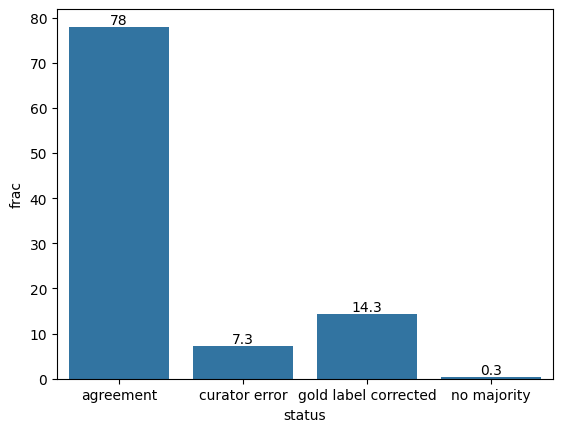

In [4]:
import seaborn as sns

fig_df = df.copy()
fig_df = fig_df[['display_id', 'freq', 'status']].drop_duplicates()
fig_df = fig_df.groupby(['status']).agg({'freq': 'sum'}).reset_index()
fig_df['frac'] = (fig_df.freq / fig_df.freq.sum()).round(3) * 100
print(fig_df)

ax = sns.barplot(data=fig_df, x='status', y='frac')
ax.bar_label(ax.containers[0])


now we need to look into what is causing the 14% correction rate

,doccano.id,doccano.text,doccano.meta,doccano.gold_label_name,display_id,doccano.username,doccano.comment,doccano.label,doccano.example.votes,doccano.example.majority_label_name,...,build_version,review.comments,review.labels,review.round,review.group_review,freq,final_label,review.gold_label_incorrect,status,category


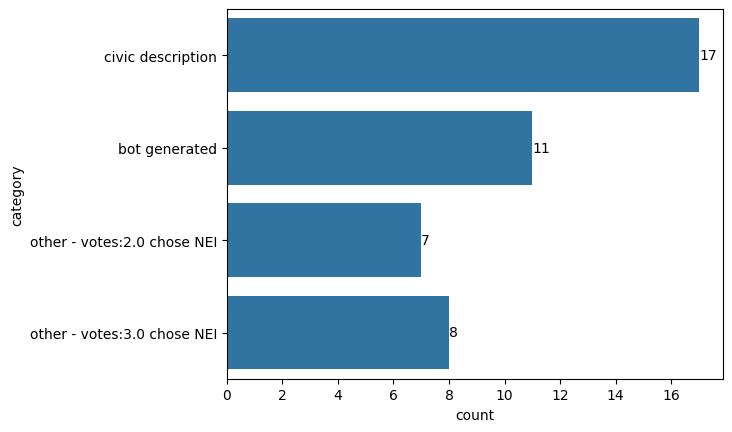

In [5]:
fig_df = df.drop_duplicates(['display_id'])  # we only care about the example level here, not the individual curator level
fig_df = fig_df[fig_df.status == 'gold label corrected']
ax = sns.countplot(data=fig_df, y='category')
ax.bar_label(ax.containers[0])
fig_df[fig_df.category =='other']

How many bot generated entries retained their label? what about civic description entries?

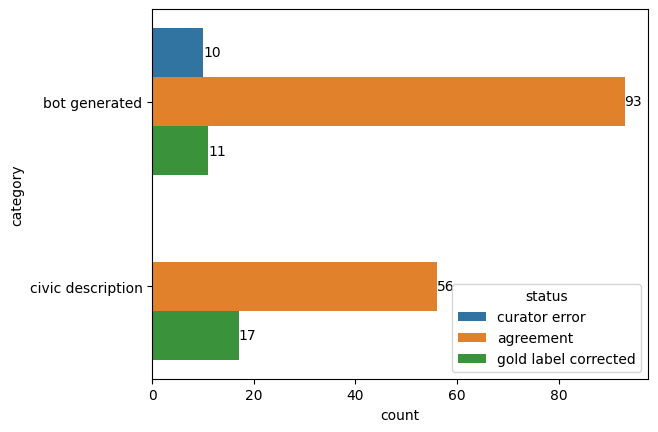

In [6]:
fig_df = df.drop_duplicates(['display_id'])  # we only care about the example level here, not the individual curator level
fig_df = fig_df[fig_df.category.isin({'bot generated', 'civic description'})]

ax = sns.countplot(data=fig_df, y='category', hue='status')

for container in ax.containers:
    ax.bar_label(container)


now lets create the target file. We want to make sure we keep the "display_id" as well as claim.hash and evidence.hash as both are useful for backtracing our data

In [7]:
df['id'] = df['id'].str.rsplit('_', 1).str[0] + '_' + df.gold_label_name
df = df.rename(columns={'final_label': 'gold_label_name', 'gold_label_name': 'doccano.original_label'})
drop = ['doccano.freq', 'status', 'category', 'freq']
df = df.drop(columns=drop)
df.columns
print(sorted(df.columns.tolist()))

['build_version', 'claim', 'claim.flat', 'claim.generated', 'claim.id', 'claim.source', 'conversation', 'display_id', 'doccano.comment', 'doccano.correct', 'doccano.example.gold_label_votes', 'doccano.example.majority_label_correct', 'doccano.example.majority_label_name', 'doccano.example.majority_label_votes', 'doccano.example.votes', 'doccano.gold_label_name', 'doccano.id', 'doccano.label', 'doccano.meta', 'doccano.original_label', 'doccano.round', 'doccano.text', 'doccano.username', 'document.doi', 'document.pmcid', 'document.pmid', 'document.title', 'evidence', 'evidence.flat', 'evidence.generated', 'evidence.id', 'evidence.source', 'generated', 'gold_label_name', 'hypothesis.tag', 'hypothesis.username', 'id', 'in_table', 'is_flagged', 'partition', 'review.comments', 'review.gold_label_incorrect', 'review.group_review', 'review.labels', 'review.round', 'score']


/var/tmp/ipykernel_3407/2023552636.py:1: FutureWarning: In a future version of pandas all arguments of StringMethods.rsplit except for the argument 'pat' will be keyword-only.
  df['id'] = df['id'].str.rsplit('_', 1).str[0] + '_' + df.gold_label_name


add the hashes

In [8]:
from article_utils.db import connect, get_or_create_textid
import json
conn = connect(relative_path('data/articles_db.sqlite'))

try:
    df['claim.hash'] = df.claim.apply(lambda claim: [c['content'] for c in claim]).apply(json.dumps)
    df['evidence.hash'] = df.evidence.apply(lambda ev: [e['content'] for e in ev]).apply(json.dumps)
    df['claim.hash'] = df['claim.hash'].apply(lambda h: get_or_create_textid(conn, h))
    df['evidence.hash'] = df['evidence.hash'].apply(lambda h: get_or_create_textid(conn, h))
finally:
    conn.close()

df[['evidence.hash', 'claim.hash', 'display_id']]

,evidence.hash,claim.hash,display_id
0,4376,4375,1b081473-9a3f-466d-80c7-773dbf02e801
1,4376,4375,1b081473-9a3f-466d-80c7-773dbf02e801
2,4376,4375,1b081473-9a3f-466d-80c7-773dbf02e801
3,5495,2332,e7029c89-5dcc-4921-b021-ece98c927ccb
4,5495,2332,e7029c89-5dcc-4921-b021-ece98c927ccb
...,...,...,...
893,2836,1153,556c44b3-04e3-4619-a3c1-6a38ffac5724
894,2836,1153,556c44b3-04e3-4619-a3c1-6a38ffac5724
895,5512,3958,dfb02990-50de-40f4-b9b9-90411165db36
896,5512,3958,dfb02990-50de-40f4-b9b9-90411165db36


now match up the output to the cleaned up comments from the comments.csv file



In [9]:
comments_df = pd.read_csv(relative_path('data/doccano/IAv2_civicfact2023.10.20/comments.tsv'), sep='\t')
comments_df = comments_df.rename(columns={
    'username': 'doccano.username',
    'comment': 'doccano.comment',
    'label': 'doccano.label',
    'comment_cleaned': 'doccano.reason'
})

result_df = df.copy()
result_df = result_df.merge(comments_df[['doccano.username', 'doccano.reason', 'doccano.comment', 'display_id', 'doccano.label']], validate='one_to_one', how='left')
result_df['doccano.reason'] = result_df['doccano.reason'].fillna('')
result_df[result_df.gold_label_name != result_df['doccano.label']][['doccano.comment', 'doccano.reason', 'claim.hash', 'evidence.hash', 'doccano.username',  'gold_label_name', 'doccano.label']]

,doccano.comment,doccano.reason,claim.hash,evidence.hash,doccano.username,gold_label_name,doccano.label
0,Should be more evidence(s) such as symptoms or...,,4375,4376,Mariam_Khanfar,SUPPORTS,NEI
2,Evidence does not mention the disease,,4375,4376,adanos,SUPPORTS,NEI
8,Gene not mentioned,,152,153,epleasance,REFUTES,NEI
12,,,2759,2760,Mariam_Khanfar,REFUTES,NEI
13,no differ compared to control group - all resp...,,2759,2760,jsaliba10,REFUTES,SUPPORTS
...,...,...,...,...,...,...,...
846,,,2028,1934,epleasance,SUPPORTS,REFUTES
855,,,5483,5511,camgrisdale,NEI,SUPPORTS
879,"the majority of the claim is supported, but no...",,5494,3583,creisle,SUPPORTS,NEI
886,,,2787,75,creisle,REFUTES,SUPPORTS


In [10]:
from article_utils.util import dump_jsonl
from nli.util import NEUTRAL_WORKFLOW_NAME

output_df = result_df.copy().rename(columns={c: c.replace('review.', 'group_review.') for c in result_df.columns if c.startswith('review.')})
assert 'doccano.original_label' in output_df.columns

example_cols = [c for c in output_df.columns if any([c.startswith(prefix) for prefix in {'claim', 'evidence', 'document'}])] + ['gold_label_name', 'id']

output_df = output_df.rename(columns={'group_review.labels': 'group_review.tags'})
review_cols= [
    'doccano.reason',
    'doccano.label',
    'doccano.comment',
    'doccano.username',
    'doccano.round',
    'doccano.original_label',
    'group_review.round',
    'group_review.tags',
    'group_review.comments',
    'group_review.validated',
    'group_review.label',
]
output_df['group_review.label'] = ''
output_df.loc[output_df['group_review.round'] != '', 'group_review.label'] = output_df['gold_label_name']

def group_validated(row):
    # did the group agree with the label from the individual rounds
    if row['group_review.round']:
        if row['gold_label_name'] == row['doccano.label']:
            return True
        return False

    return None

output_df['group_review.validated'] = output_df.apply(group_validated, axis=1)
print(output_df.columns)


output_df = output_df.groupby(['display_id']).apply(
lambda subset_df: subset_df[review_cols].rename(
    columns={c: c.replace('doccano.', '').replace('.', '_') for c in review_cols}
).fillna('').to_dict('records')).reset_index()
output_df.columns = ['display_id', 'reviews']
output_df = output_df.merge(result_df[['display_id'] + example_cols].drop_duplicates(['display_id']))
for _, row in output_df.iterrows():
    print(row)
    print(row['reviews'])
    break


for col in ['document.pmid', 'claim.id', 'evidence.id']:
    # stuff out of doccano may be getting type-cast
    output_df[col] = output_df[col].astype(str)

claim_source = {
    'generated from opposing terms': 'civic flipped significance',
    'generated': NEUTRAL_WORKFLOW_NAME
}
output_df['claim.source'] = output_df['claim.source'].apply(lambda source: claim_source.get(source, source))
output_df['evidence.selection_method'] = NEUTRAL_WORKFLOW_NAME

print(output_df[['claim.source', 'evidence.source', 'claim.generated', 'evidence.generated']].value_counts())
dump_jsonl(output_df, relative_path('data/doccano/IAv2_civicfact2023.10.20/reviews.jsonl'))

Index(['doccano.id', 'doccano.text', 'doccano.meta', 'doccano.gold_label_name',
       'display_id', 'doccano.username', 'doccano.comment', 'doccano.label',
       'doccano.example.votes', 'doccano.example.majority_label_name',
       'doccano.example.majority_label_votes',
       'doccano.example.gold_label_votes', 'doccano.correct',
       'doccano.example.majority_label_correct', 'doccano.round', 'claim',
       'claim.flat', 'claim.generated', 'claim.id', 'claim.source',
       'conversation', 'document.doi', 'document.pmcid', 'document.pmid',
       'document.title', 'evidence', 'evidence.flat', 'evidence.generated',
       'evidence.id', 'evidence.source', 'generated', 'doccano.original_label',
       'hypothesis.tag', 'hypothesis.username', 'id', 'in_table', 'is_flagged',
       'partition', 'score', 'build_version', 'group_review.comments',
       'group_review.tags', 'group_review.round', 'group_review.group_review',
       'gold_label_name', 'group_review.gold_label_incorrect